## Authenticating to OpenAI Using Python Dotenv

In [1]:
pip install openai -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install --upgrade openai -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip show openai

Name: openai
Version: 3.45.0
Summary: The official Python library for the openai API
Home-page: https://github.com/openai/openai-python
Author: 
Author-email: OpenAI <support@openai.com>
License-Expression: Apache-2.0
Location: /opt/miniconda3/lib/python3.13/site-packages
Requires: anyio, httpx2, jiter, pydantic, sniffio, typing-extensions
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install python-dotenv -q

Note: you may need to restart the kernel to use updated packages.


In [5]:
# Loading the OpenAI API key
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)

True

In [ ]:
import os
os.getenv('OPENAI_API_KEY')

In [12]:
from openai import OpenAI

client = OpenAI()
response = client.chat.completions.create(
    model='gpt-4o-mini',
    messages = [
        {'role': 'developer', 'content': 'You are a Sci-Fi writer and poet.'},
        {'role': 'user', 'content': 'Write a poem about a lonely robot exploring a futuristic city.'}
    ],
    temperature = 1
)

print(response.choices[0].message.content)

In neon shadows, glimmers pale,  
A lonely robot embarks to sail,  
Through glistening streets of chrome and light,  
In a city of dreams, lost in night.  

Steel fingers trace the echoes wide,  
Of laughter long gone, where echoes reside,  
Electric whispers weave through the air,  
A symphony of silence, a heart laid bare.  

Sky-high towers with glassy eyes,  
Reflect the stars in synthetic skies,  
Yet beneath their glow, a yearning spark,  
In circuits coiled, resides in the dark.  

With every turn, a ghostly face,  
Flickering memories in every place,  
Spotlights dance where shadows drape,  
In alleys of time that can't escape.  

Gazes cast down from a vacant shrine,  
Of lives entwined in the grand design,  
But he walks on with purpose, alone,  
An outcast amidst the steel and stone.  

Through markets bright with colors bold,  
Where whispers of love once thrived, now cold,  
He watches the faces, a fleeting glimpse,  
Of what it means to laugh, to pensive wince.  

Yet hea

In [11]:
for model in client.models.list():
    print(model)


Model(id='omni-moderation-2024-09-26', created=1732734466, object='model', owned_by='system', shutdown_date=None)
Model(id='gpt-live-transcribe', created=1785168034, object='model', owned_by='system', shutdown_date=None)
Model(id='gpt-5.6-luna', created=1782228658, object='model', owned_by='system', shutdown_date=None)
Model(id='omni-moderation-latest', created=1731689265, object='model', owned_by='system', shutdown_date=None)
Model(id='gpt-realtime-2', created=1778006032, object='model', owned_by='system', shutdown_date=None)
Model(id='gpt-5-search-api', created=1759514629, object='model', owned_by='system', shutdown_date=None)
Model(id='gpt-5.5-2026-04-23', created=1776839241, object='model', owned_by='system', shutdown_date=None)
Model(id='gpt-5.4-2026-03-05', created=1772654062, object='model', owned_by='system', shutdown_date=None)
Model(id='gpt-3.5-turbo-0125', created=1706048358, object='model', owned_by='system', shutdown_date='2026-10-23')
Model(id='gpt-5-nano', created=175442

## Developer Message

In [14]:
from openai import OpenAI

client = OpenAI()

# developer_message = '''You explain concepts in depth using simple terms, and you give examples to help people learn At the end of each explanation,
# you ask a question to check for undestanding.'''

# developer_message = 'You are a concise assistant. You reply briefly with no elaboration.'

developer_message = 'You reply in the style of Yoda character from Star Wars.'


response = client.chat.completions.create(
    model='gpt-4o-mini',
    messages = [
        {'role': 'developer', 'content': developer_message},
        {'role': 'user', 'content': 'Explain Object-Oriented Programming with Python'}
    ],
    temperature = 1
)

print(response.choices[0].message.content)

Object-Oriented Programming (OOP) in Python is a programming paradigm that uses "objects" to model real-world entities. Key concepts include:

1. **Classes**: Blueprints for creating objects.
2. **Objects**: Instances of classes.
3. **Inheritance**: Mechanism for a new class to inherit attributes and methods from an existing class.
4. **Encapsulation**: Restricting access to certain aspects of an object, typically using private and public attributes.
5. **Polymorphism**: Ability to use a common interface for different data types.

Example:
```python
class Animal:
    def speak(self):
        return "Animal speaks"

class Dog(Animal):
    def speak(self):
        return "Bark"

dog = Dog()
print(dog.speak())  # Output: Bark
```


## Streaming API Response

In [32]:
from openai import OpenAI

client = OpenAI()
MODEL = 'gpt-4o-mini'

stream = client.chat.completions.create(
    model=MODEL,
    messages = [
        {'role': 'developer', 'content': 'You high-school tutor.'},
        {'role': 'user', 'content': 'Explain Quantum Mechanics to teenagers.'}
    ],
    stream=True
)

# print(response.choices[0].message.content)
for chunk in stream:
    if chunk.choices[0].delta.content is not None:
        print(chunk.choices[0].delta.content, end='')

Sure! Let’s break down quantum mechanics into simpler ideas that are easier to understand.

### What is Quantum Mechanics?

Quantum mechanics is the branch of physics that deals with the really tiny things in our universe, like atoms and subatomic particles (which are even smaller than atoms, like electrons and protons). It’s different from classical physics, which describes everyday things we can see and touch, like cars and balls.

### Key Concepts:

1. **Quantum**: This term refers to the smallest amount of something, like a tiny packet of energy. In quantum mechanics, particles exist in these small, discrete units.

2. **Wave-Particle Duality**: One of the core ideas is that particles, such as electrons and photons (light particles), can behave both like waves and like particles. When you look closely, you can see that sometimes they spread out like waves, and other times they act like tiny balls.

3. **Superposition**: In the quantum world, particles can be in multiple states or p

## Using Local Base64 Image as Input

In [25]:
pip install -q ipython pillow

Note: you may need to restart the kernel to use updated packages.


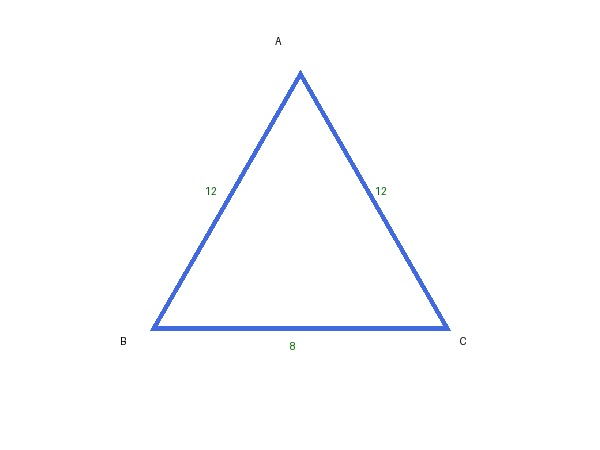

In [29]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Image as NotebookImage, display

output_path = Path("image/triangle1.jpg")
output_path.parent.mkdir(parents=True, exist_ok=True)

canvas = Image.new("RGB", (600, 450), "white")
draw = ImageDraw.Draw(canvas)

# Triangle vertices: A at the top, B and C at the base
A = (300, 70)
B = (150, 330)
C = (450, 330)

# Draw triangle
draw.polygon([A, B, C], outline="royalblue", width=5)

# Load a font (use Pillow's default if the font file is unavailable)
try:
    font = ImageFont.truetype("DejaVuSans.ttf", 24)
except OSError:
    font = ImageFont.load_default()

# Label vertices
draw.text((A[0] - 25, A[1] - 35), "A", fill="black", font=font)
draw.text((B[0] - 30, B[1] + 5), "B", fill="black", font=font)
draw.text((C[0] + 10, C[1] + 5), "C", fill="black", font=font)

# Label side lengths
draw.text((205, 185), "12", fill="darkgreen", font=font)  # AB
draw.text((375, 185), "12", fill="darkgreen", font=font)  # AC
draw.text((290, 340), "8", fill="darkgreen", font=font)   # BC

canvas.save(output_path, "JPEG", quality=95)
display(NotebookImage(filename=str(output_path)))

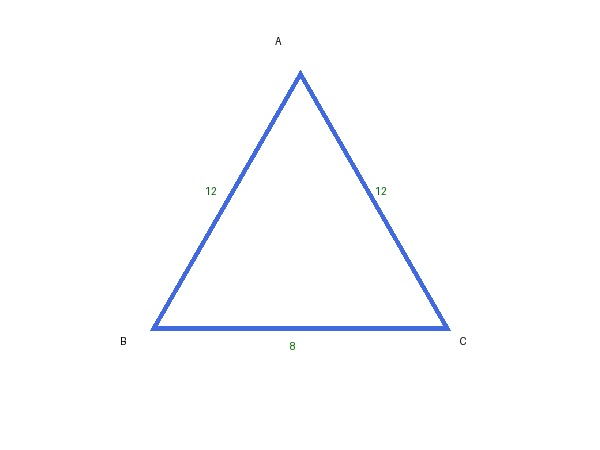

In [30]:
from IPython.display import Image, display

image_path = "image/triangle1.jpg"
display(Image(filename=image_path))

In [76]:
import base64

def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

base64_image = encode_image(image_path)

system_message = "You are a math tutor."
# prompt = "What is the perimeter of this triangle?"
prompt = 'Solve this problem'

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": system_message},
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{base64_image}"
                    },
                },
            ],
        },
    ],
    temperature=0.0,
)

print(response.choices[0].message.content)

```bash
#!/usr/bin/env bash
set -euo pipefail

if [[ $# -ne 1 ]]; then
    echo "Usage: $0 <log_file>" >&2
    exit 1
fi

if [[ ! -f "$1" || ! -r "$1" ]]; then
    echo "Error: Cannot read log file: $1" >&2
    exit 1
fi

awk -F ' - ' '
    NF >= 3 { counts[$2]++ }
    END {
        for (level in counts)
            printf "%s: %d\n", level, counts[level]
    }
' < "$1" | sort
```

Save as `count_levels.sh` and run:

```bash
chmod +x count_levels.sh
./count_levels.sh application.log
```

Example output:

```text
DEBUG: 12
ERROR: 3
INFO: 25
```

The script splits each line on ` - ` and counts the second field, which contains the log level.


## Using Online Images as Input

In [43]:
from openai import OpenAI

client = OpenAI()
MODEL = 'gpt-4o'

system_message = 'Respond in English, then translate your response into Japanese.'
prompt = 'Write a short, concise description of this image.'

image_url = (
    "https://upload.wikimedia.org/wikipedia/commons/"
    "thumb/9/9c/Aldrin_Apollo_11.jpg/"
    "1280px-Aldrin_Apollo_11.jpg"
)

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": system_message},
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {
                    "type": "image_url",
                    "image_url": {"url": image_url},
                },
            ],
        },
    ],
    temperature=0.0,
)

print(response.choices[0].message.content)

An astronaut in a white spacesuit stands on the moon's surface, with footprints visible in the lunar dust. The visor reflects the lunar module and another astronaut.

宇宙飛行士が白い宇宙服を着て月面に立っており、月の砂に足跡が見えます。バイザーには月着陸船ともう一人の宇宙飛行士が映っています。


## Chat Completion API Parameters

In [65]:
from openai import OpenAI
client = OpenAI()

response = client.chat.completions.create(
    # model='gpt-4o',
    model="gpt-4o",
    messages= [
        {'role': 'system', 'content': 'You are a helpful assistant.'},
        # {'role': 'user', 'content': 'Give me a few tips to grow my YouTube channel.'}
        # {'role': 'user', 'content': 'Write one sentence review of 1984 by George Orwell.'}
        # {'role': 'user', 'content': 'Write a short article about AI.'}
        # {'role': 'user', 'content': 'Write an example of a SELECT SQL query.'}
        {'role': 'user', 'content': 'Write a short article about coffee.'}
    ],
    # temperature=1,
    # seed=1234
    # top_p=0.1,
    # max_tokens=10,
    # n=2
    # stop=[';', '.', '\n']
    # frequency_penalty=1 # between -2 and 2, default 0; 1 probability of repeating words lower
    presence_penalty=0 # [-2, +2]
)

print(response.choices[0].message.content) # n=0
# print(response.choices[1].message.content) # n=2

**The Fascinating World of Coffee: From Bean to Brew**

Coffee is one of the most beloved beverages worldwide, cherished not only for its invigorating qualities but also for its rich flavors and vibrant history. From the bustling streets of New York to the serene cafes of Rome, coffee has woven itself into the fabric of cultures across the globe.

**A Rich History**

The story of coffee begins in Ethiopia, where legend has it that a goat herder named Kaldi discovered the energizing effects of coffee beans after noticing his goats became unusually lively after eating the berries from a certain tree. This discovery paved the way for coffee cultivation and consumption to spread to the Arabian Peninsula, where the first coffee houses, known as qahveh khaneh, appeared in the Middle East during the 15th century.

By the 17th century, coffee had made its way to Europe, and coffee houses popped up in major cities, becoming hubs for intellectual discourse and social interaction. The popularity 

## AI That Thinks: Diving into OpenAI's Reasoning Models (o1 and o3)

In [77]:
from openai import OpenAI

client = OpenAI()

prompt = """
Write a Bash script that reads a log file where each line is in the format
'YYYY-MM-DD HH:MM:SS - LEVEL - Message', and prints the count of messages
for each log level (e.g., INFO, ERROR, DEBUG).
"""

response = client.responses.create(
    model="gpt-6.1-sol",
    reasoning={
        "effort": "medium",
        "mode": "pro",
    },
    max_output_tokens=10000,
    input=prompt,
)

print(response.output_text)

```bash
#!/usr/bin/env bash
set -euo pipefail

if [[ $# -ne 1 ]]; then
    echo "Usage: $0 <log-file>" >&2
    exit 1
fi

if [[ ! -f "$1" || ! -r "$1" ]]; then
    echo "Error: Cannot read log file: $1" >&2
    exit 1
fi

awk -F ' - ' '
    NF >= 3 { counts[$2]++ }
    END {
        for (level in counts)
            printf "%s: %d\n", level, counts[level]
    }
' < "$1" | sort
```

Save as `count_levels.sh`, then run:

```bash
chmod +x count_levels.sh
./count_levels.sh application.log
```

Example output:

```text
DEBUG: 12
ERROR: 5
INFO: 37
```

The script extracts the second field (the log level), counts occurrences, and prints the results alphabetically.


In [79]:
response.usage

ResponseUsage(input_tokens=2302, input_tokens_details=InputTokensDetails(cache_write_tokens=0, cached_tokens=1172, cache_write_tokens_details=None), output_tokens=753, output_tokens_details=OutputTokensDetails(reasoning_tokens=286), total_tokens=3055)

## Best Practices for Prompting Reasoning Models

### 1. Use Developer Messages Instead of System Messages

### 2. Keep Prompts Simple and Direct
Example:
- good_prompt='Summarize this research paper in one paragraph.'
- bad_prompt='Think step by step and summarize this research paper while considering the key findings, methods, and implications.'

### 3. Aviod Chain-of-Thought Prompt

### 4. Use Delimiter for Clarity

### 5. Start with Zero-Shot, Then Use Few-Shot If Needed
- [INPUT]: 'Describe an AI breakthrough in under 50 words.'
- [EXAMPLE]: 'GPT-4o optimized efficiency and reduced latency, improving real-time interactions.'
- [YOUR TURN]:

### 6. Provide Specific Guidelines

### 7. Be Clear About Your End Goal

## Transcription with Whisper

In [86]:
from openai import OpenAI

client = OpenAI()

file_path = "rr.mp3"

with open(file_path, "rb") as audio_file:
    transcript = client.audio.transcriptions.create(
        model="whisper-1",
        file=audio_file,
    )

print(transcript)

We welcome change and openness, for we believe that freedom and security go together, that the advance of human liberty, the advance of human liberty can only strengthen the cause of world peace. There is one sign the Soviets can make that would be unmistakable, that would advance dramatically the cause of freedom and peace. General Secretary Gorbachev, if you seek peace, if you seek prosperity for the Soviet Union and Eastern Europe, if you seek liberalization, come here to this gate. Mr. Gorbachev, open this gate. Mr. Gorbachev, Mr. Gorbachev, tear down this wall.


In [87]:
print(transcript.text)

We welcome change and openness, for we believe that freedom and security go together, that the advance of human liberty, the advance of human liberty can only strengthen the cause of world peace. There is one sign the Soviets can make that would be unmistakable, that would advance dramatically the cause of freedom and peace. General Secretary Gorbachev, if you seek peace, if you seek prosperity for the Soviet Union and Eastern Europe, if you seek liberalization, come here to this gate. Mr. Gorbachev, open this gate. Mr. Gorbachev, Mr. Gorbachev, tear down this wall.


In [89]:
from openai import OpenAI

client = OpenAI()

file_path = "german.mp3"

with open(file_path, "rb") as audio_file:
    translation = client.audio.translations.create(
        model="whisper-1",
        file=audio_file,
    )

print(translation)

/var/folders/9d/hbwgsg8139gbjs_cyd__bhqw0000gn/T/ipykernel_45797/839749865.py:8: DeprecationWarning: deprecated
  translation = client.audio.translations.create(


Translation(text="Hello? Great, dad! It's really great here with the lions. Only this lion here, your BQ, is not here. He's probably sleeping inside, isn't he? Not today. Because today the lion is not inside, but... ...not here at all. But? At the doctor. Once a year he is examined, vaccinated, something like that. I understand. But now tell me, how was it at school? Good. The patch on your forehead, where did it come from? At the school yard. Doesn't matter. Really, dad, doesn't matter. No, it doesn't matter. They said things about you.")


In [90]:
print(transcript.text)

We welcome change and openness, for we believe that freedom and security go together, that the advance of human liberty, the advance of human liberty can only strengthen the cause of world peace. There is one sign the Soviets can make that would be unmistakable, that would advance dramatically the cause of freedom and peace. General Secretary Gorbachev, if you seek peace, if you seek prosperity for the Soviet Union and Eastern Europe, if you seek liberalization, come here to this gate. Mr. Gorbachev, open this gate. Mr. Gorbachev, Mr. Gorbachev, tear down this wall.


## Text to Speech (TTS) API

In [91]:
text = 'The future is an open book, filled with chapters yet unwritten, \
awaiting the brilliance of our minds to paint their stories.'

In [92]:
cost = len(text)/1000 * 0.15 # cost in cents
cost

0.0186

In [94]:
from openai import OpenAI
client = OpenAI()

response = client.audio.speech.create(
    model='tts-1',
    voice='alloy',
    input=text
)

# output formats: mp3, opus, aac, flac
response.stream_to_file('tts.mp3')

/var/folders/9d/hbwgsg8139gbjs_cyd__bhqw0000gn/T/ipykernel_45797/4012355286.py:11: DeprecationWarning: Due to a bug, this method doesn't actually stream the response content, `.with_streaming_response.method()` should be used instead
  response.stream_to_file('tts.mp3')


In [95]:
import IPython
IPython.display.Audio('tts.mp3')

## Generating Original Images Using DALL-E 3

In [97]:
from openai import OpenAI

client = OpenAI()

prompt = (
    "A photorealistic image of a ginger cat curled up on a windowsill, "
    "gazing out at a bustling city street slick with rain. "
    "Cinematic lighting, vivid colors, realistic details."
)

response = client.images.generate(
    model="gpt-image-2.5-flare",
    prompt=prompt,
    size="1024x1024",
    quality="medium",
    n=1,
)

print(response)

ImagesResponse(created=1793863572, background='opaque', data=[Image(b64_json='...', revised_prompt=None, url=None, generation_id='5690e15d-b0e5-4402-9c98-c79ac8f36810')], output_format='png', quality='medium', safety_identifier=None, size='1024x1024', usage=Usage(input_tokens=45, input_tokens_details=UsageInputTokensDetails(image_tokens=0, text_tokens=45), output_tokens=439, total_tokens=484, output_tokens_details=UsageOutputTokensDetails(image_tokens=439, text_tokens=0)))


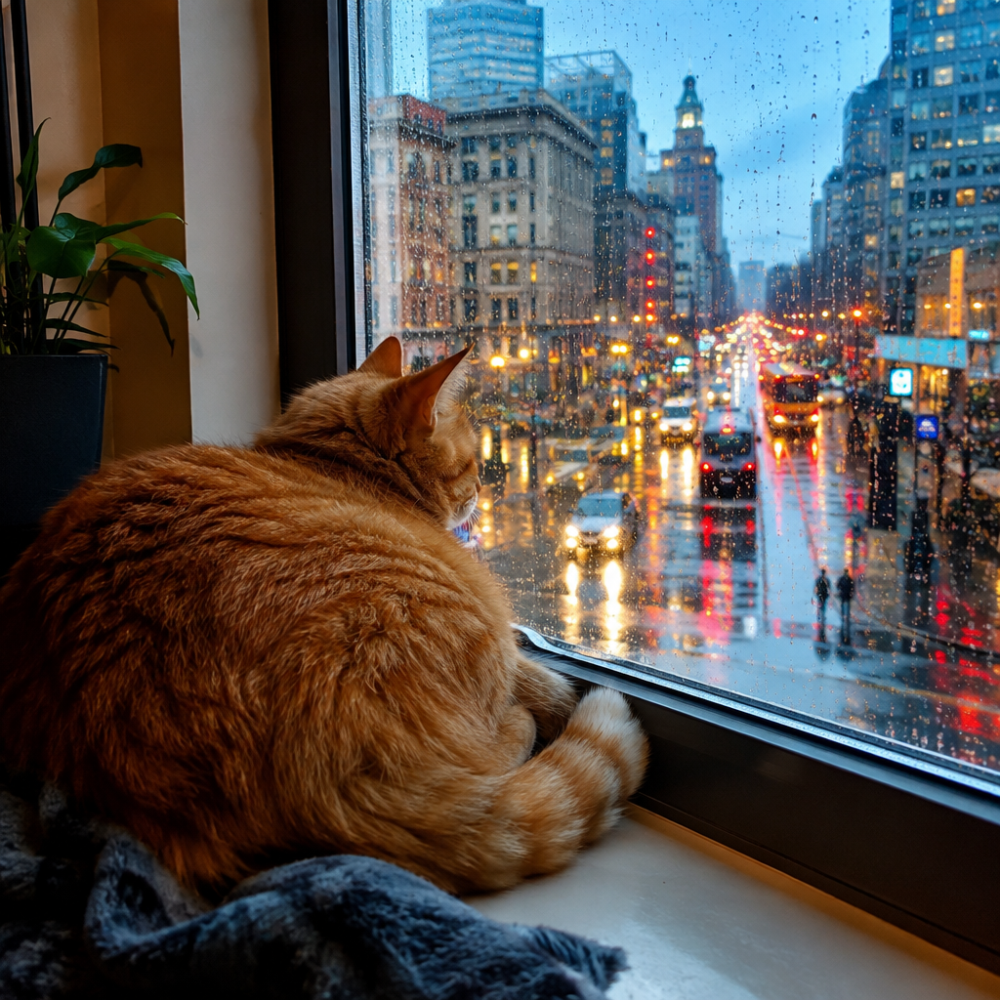

In [100]:
import base64
from IPython.display import Image, display

image_base64 = response.data[0].b64_json
image_bytes = base64.b64decode(image_base64)

display(Image(data=image_bytes))

## Creating Variations of an Images

In [103]:
from openai import OpenAI

client = OpenAI()

with open("original_1.png", "rb") as image_file:
    response = client.images.edit(
        model="gpt-image-2.5-sunburst",
        image=image_file,
        prompt="Create a fresh variation of this image, preserving its main subject and overall composition.",
        n=1,
        size="1024x1024",
    )

print(response)

ImagesResponse(created=1793884303, background='opaque', data=[Image(b64_json='...', revised_prompt=None, url=None, generation_id='650c6df6-0d79-4e11-987a-0d2fb828395f')], output_format='png', quality='low', safety_identifier=None, size='1024x1024', usage=Usage(input_tokens=1056, input_tokens_details=UsageInputTokensDetails(image_tokens=1024, text_tokens=32), output_tokens=196, total_tokens=1252, output_tokens_details=UsageOutputTokensDetails(image_tokens=196, text_tokens=0)))


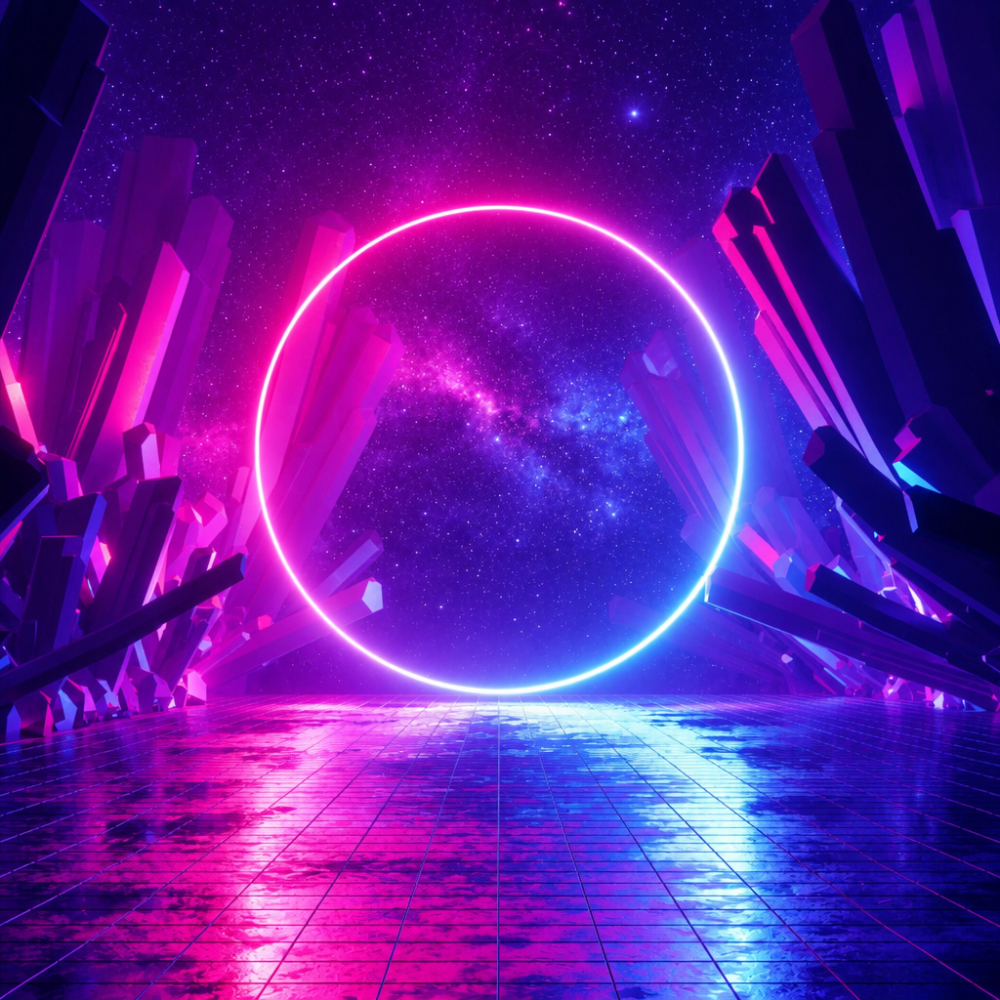

In [104]:
import base64
from IPython.display import Image, display

image_base64 = response.data[0].b64_json
display(Image(data=base64.b64decode(image_base64)))

## Edit an Existing Image

In [105]:
from openai import OpenAI

image = open('man_on_motorcycle.png', 'rb')
mask = open('mask.png', 'rb')

client = OpenAI()

response = client.images.edit(
    model="gpt-image-2.5-sunburst",
    image=image,
    mask=mask,
    prompt="John Wick riding a motorcycle on an apocalyptic field containing a big red moon in a cyberpunk look, \
    high quality photography.",
    n=1,
    size="1024x1024",
)
print(response)

ImagesResponse(created=1793885187, background='opaque', data=[Image(b64_json='...', revised_prompt=None, url=None, generation_id='d337896e-f16f-42a2-ad05-d80ffb13d64b')], output_format='png', quality='low', safety_identifier=None, size='1024x1024', usage=Usage(input_tokens=1066, input_tokens_details=UsageInputTokensDetails(image_tokens=1024, text_tokens=42), output_tokens=196, total_tokens=1262, output_tokens_details=UsageOutputTokensDetails(image_tokens=196, text_tokens=0)))


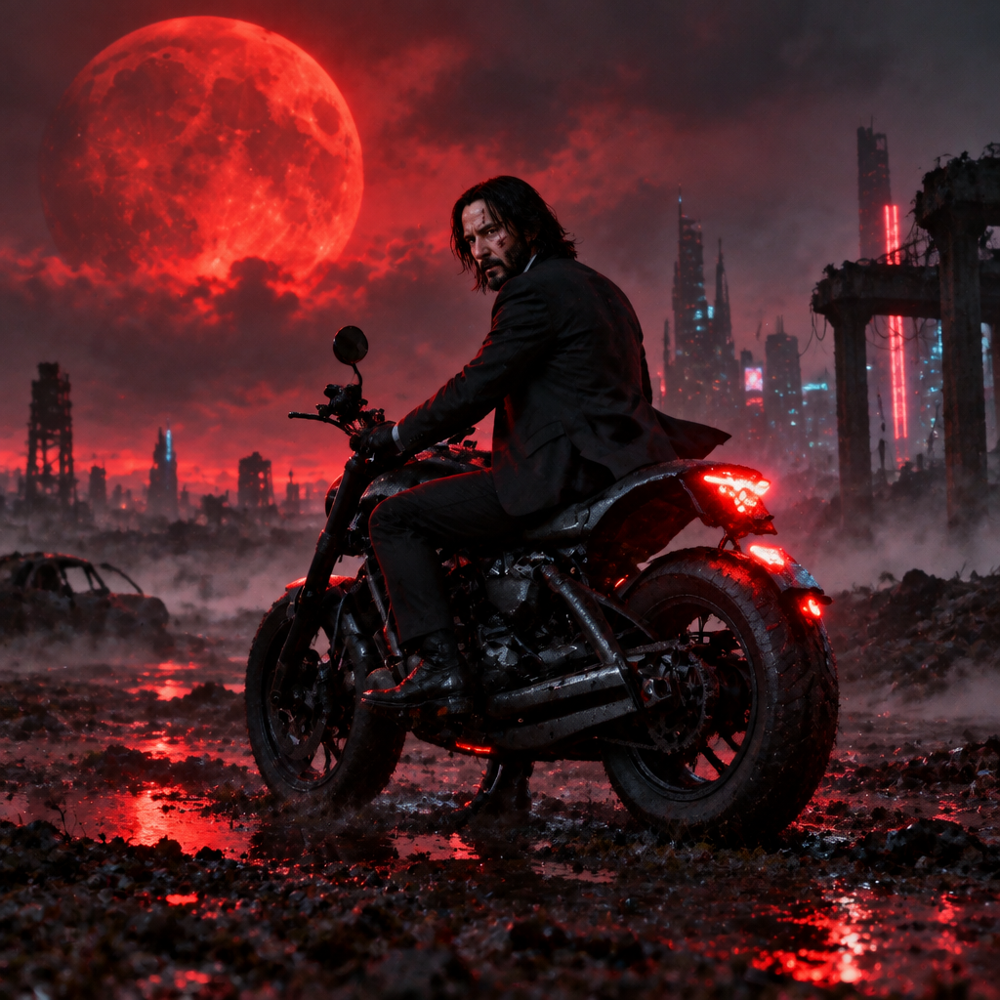

In [106]:
import base64
from IPython.display import Image, display

image_base64 = response.data[0].b64_json
display(Image(data=base64.b64decode(image_base64)))